# Loading the models

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error


TUNER_RESULTS_FOLDER = "../../data/tuner_results"
model_with_t = joblib.load(f"{TUNER_RESULTS_FOLDER}/with/refit_best_model.mod")
model_wout_t = joblib.load(f"{TUNER_RESULTS_FOLDER}/wout/refit_best_model.mod")

# Loading the catalogue data

In [2]:
CATALOG_PATH = "../../data/catalogue_data_021026.csv"

catalog = pd.read_csv(CATALOG_PATH)
catalog.dropna(how="all", axis=0, inplace=True)
catalog

,source,radio,association,class,distance(kpc),l(deg),b(deg),period(s),pdot(1e-11s/s),pdot_ul,...,Err_kT_min,kT_min_ul,lumin_peak,kT_max,Err_kT_max,kT_max_ul,Err_lum_down(1e33erg/s),Err_lum_up(1e33erg/s),Err_tau_real_down(kyr),Err_tau_real_up(kyr)
0,CXOUJ185238.6+0040,NaN,SNR Kes79,CCO,7.10,33.667347,0.038728,0.105,8.700000e-07,NaN,...,0.001,NaN,NaN,NaN,NaN,NaN,0.420,0.420,1.20,1.20
1,1E1207.4-5209,NaN,SNR G296.5+10.0,CCO,2.35,296.545164,9.916088,0.424,2.200000e-06,NaN,...,0.100,NaN,NaN,NaN,NaN,NaN,4.980,2.270,2.30,2.30
2,RXJ0822.0-4300,NaN,SNR PuppisA,CCO,1.30,260.572541,-3.495317,0.113,9.300000e-07,NaN,...,0.050,NaN,NaN,NaN,NaN,NaN,1.000,1.000,0.50,0.50
3,1E161348-5055,NaN,SNR RCW103,CCO,3.30,332.428951,-0.373763,24030.000,7.000000e+01,True,...,0.100,NaN,220.0,1.2,0.1,NaN,1.000,1.000,1.80,1.80
4,CXOJ085201.4-461753,NaN,SNR Vela Jr,CCO,0.77,266.234600,-1.194200,NaN,NaN,NaN,...,0.010,NaN,NaN,NaN,NaN,NaN,0.060,0.060,1.25,1.25
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,RXJ2143.0+0654,NaN,NaN,XDINS,0.43,62.657328,-33.139952,9.428,4.100000e-03,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
72,RXJ0720.4-3125,NaN,NaN,XDINS,0.29,244.158050,-8.164527,8.391,6.983000e-03,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.034,0.034,15.00,15.00
73,RXJ0806.4-4123,NaN,NaN,XDINS,0.25,257.426088,-4.984389,11.370,5.500000e-03,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
74,RXJ1308.6+2127,NaN,NaN,XDINS,0.50,338.745669,83.081296,10.310,1.100000e-02,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.003,0.003,100.00,100.00


# Filter the data and apply the models

In [3]:
results = catalog.copy()

def lognnan(x):
    """Get the log10 of an array, returning NaN for non-finite values."""
    return np.where(np.isfinite(x), np.log10(x), np.nan)

results["logP_true"] = lognnan(catalog["period(s)"])
results["logPdot_true"] = lognnan(catalog["pdot(1e-11s/s)"] * 1.0e-11)
results["logL_true"] = lognnan(catalog["luminosity_bol_qui(e33erg/s)"] * 1.0e33)
results["logt_true"] = lognnan(catalog["tau_real(kyr)"] * 1.0e3)
results["logB_true"] = lognnan(catalog["Bp(e14G)"] * 1.0e14)

X = results.rename(
    columns={col: col.split("_true")[0] for col in results.columns})

X_scaled = model_wout_t.transformer.transform("X", X)
in_bounds = (X_scaled.min(axis=1) >= 0) & (X_scaled.max(axis=1) <= 1)
print(f"{sum(in_bounds)} sources with defined inputs, and in bounds "
      f"[{100*np.mean(in_bounds):.1f}%].")
results["in_bounds"] = in_bounds

X_scaled2 = model_with_t.transformer.transform("X", X)
in_bounds2 = (X_scaled2.min(axis=1) >= 0) & (X_scaled2.max(axis=1) <= 1)

assert not (~in_bounds & in_bounds2).any()

Y_reg_wout, Y_cls_wout = model_wout_t.predict(X)
Y_reg_wout.index = results.index
Y_cls_wout.index = results.index

Y_reg_with, Y_cls_with = model_with_t.predict(X)
Y_reg_with.index = results.index
Y_cls_with.index = results.index

Y_reg_with[~in_bounds2] = np.nan
Y_reg_wout[~in_bounds] = np.nan
Y_cls_with[~in_bounds2] = np.nan
Y_cls_wout[~in_bounds] = np.nan

wout_cols = {col: col + "_pred_wout"for col in Y_reg_wout.columns}
with_cols = {col: col + "_pred_with" for col in Y_reg_with.columns}
results = pd.concat([results, Y_reg_wout.rename(columns=wout_cols)],
                    axis=1, ignore_index=False)
results["envelope_wout"] = Y_cls_wout
results = pd.concat([results, Y_reg_with.rename(columns=with_cols)],
                    axis=1, ignore_index=False)
results["envelope_with"] = Y_cls_with

results.to_csv("../../results/catalog_results.csv", index_label="index")
results

51 sources with defined inputs, and in bounds [69.9%].


,source,radio,association,class,distance(kpc),l(deg),b(deg),period(s),pdot(1e-11s/s),pdot_ul,...,in_bounds,logB_pred_wout,M_pred_wout,logB0_pred_wout,logt_pred_wout,envelope_wout,logB_pred_with,M_pred_with,logB0_pred_with,envelope_with
0,CXOUJ185238.6+0040,NaN,SNR Kes79,CCO,7.10,33.667347,0.038728,0.105,8.700000e-07,NaN,...,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1E1207.4-5209,NaN,SNR G296.5+10.0,CCO,2.35,296.545164,9.916088,0.424,2.200000e-06,NaN,...,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,RXJ0822.0-4300,NaN,SNR PuppisA,CCO,1.30,260.572541,-3.495317,0.113,9.300000e-07,NaN,...,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1E161348-5055,NaN,SNR RCW103,CCO,3.30,332.428951,-0.373763,24030.000,7.000000e+01,True,...,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,CXOJ085201.4-461753,NaN,SNR Vela Jr,CCO,0.77,266.234600,-1.194200,NaN,NaN,NaN,...,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,RXJ2143.0+0654,NaN,NaN,XDINS,0.43,62.657328,-33.139952,9.428,4.100000e-03,NaN,...,True,13.426386,1.490177,14.380429,5.697321,1.0,NaN,NaN,NaN,NaN
72,RXJ0720.4-3125,NaN,NaN,XDINS,0.29,244.158050,-8.164527,8.391,6.983000e-03,NaN,...,True,13.505513,1.785344,14.341165,5.605628,1.0,13.546233,1.159809,14.057027,1.0
73,RXJ0806.4-4123,NaN,NaN,XDINS,0.25,257.426088,-4.984389,11.370,5.500000e-03,NaN,...,True,13.508372,1.141909,14.368550,5.807432,1.0,NaN,NaN,NaN,NaN
74,RXJ1308.6+2127,NaN,NaN,XDINS,0.50,338.745669,83.081296,10.310,1.100000e-02,NaN,...,True,13.646963,1.617019,14.438653,5.634496,1.0,NaN,NaN,NaN,NaN


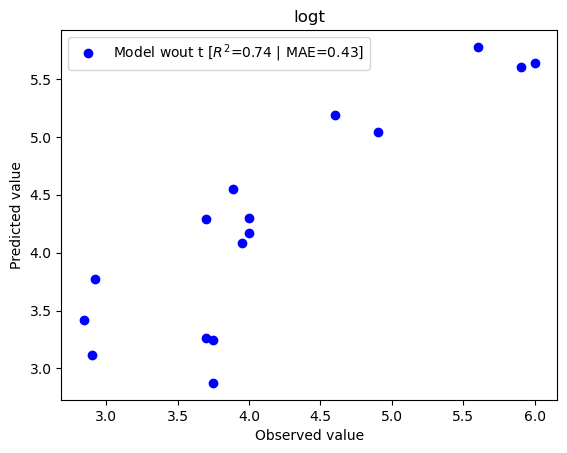

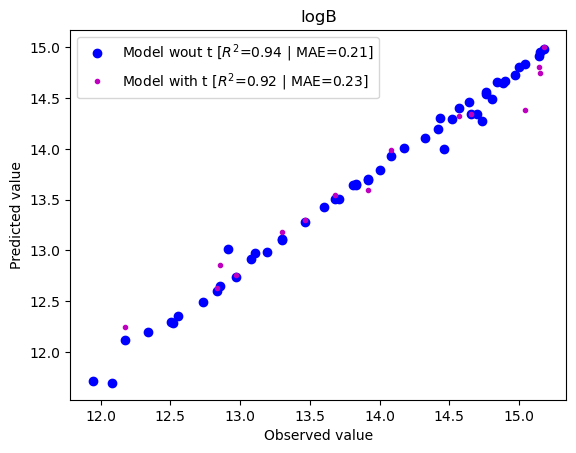

In [4]:

for obs_col in results.columns:
    if not obs_col.endswith("_true"):
        continue
    observed = results[obs_col]

    col = obs_col.split("_true")[0]
    col_wout, col_with  = [col + suffix for suffix in ["_pred_wout", "_pred_with"]]
    if col_with not in results.columns and col_wout not in results.columns:
        continue

    plt.figure()
    plt.title(col)
    plt.xlabel("Observed value")
    plt.ylabel("Predicted value")
    for pred_col, model_label, color in zip([col_wout, col_with],
                                            ["Model wout t", "Model with t"],
                                            ["b", "m"]):
        if pred_col in results.columns:
            predicted = results[pred_col]

            ok = np.isfinite(observed + predicted)
            r2 = r2_score(observed[ok], predicted[ok])
            mae = mean_absolute_error(observed[ok], predicted[ok])
            label = f"{model_label} [$R^2$={r2:.2f} | MAE={mae:.2f}]"
            plt.plot(observed[ok], predicted[ok],
                     "o" if color=="b" else ".", color=color, label=label)
    plt.legend(loc="best")
    plt.show()

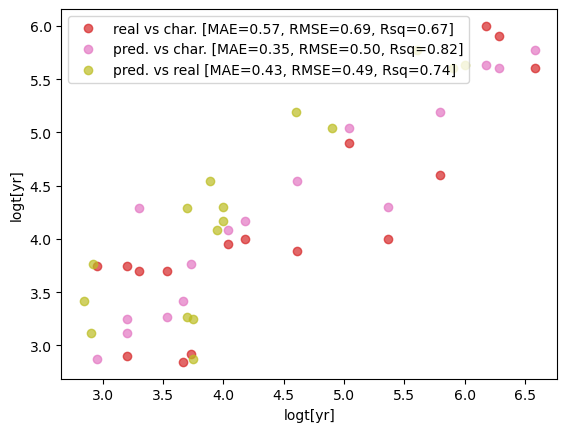

In [5]:

plt.figure()
logt_c = np.log10(results["tau_c(kyr)"] * 1000)
logt = results["logt_true"].copy()
logt_pred = results["logt_pred_wout"].copy()
ok = np.isfinite(logt + logt_pred + logt_c)
logt, logt_pred, logt_c = logt[ok], logt_pred[ok], logt_c[ok]

def mae_str(x, y):
    """Get the mean absolute error string for two arrays."""
    maerr = np.mean(np.abs(x - y))
    rmse = np.sqrt(np.mean((x-y)**2.0))
    mr = r2_score(x, y)
    return f" [MAE={maerr:.2f}, RMSE={rmse:.2f}, Rsq={mr:.2f}]"

plt.plot(logt_c, logt, "o", color="C3", alpha=0.7,
         label="real vs char." + mae_str(logt_c, logt))
plt.plot(logt_c, logt_pred, "o", color="C6", alpha=0.7,
         label="pred. vs char." + mae_str(logt_c, logt_pred))
plt.plot(logt, logt_pred, "o", color="C8", alpha=0.7,
         label="pred. vs real" + mae_str(logt, logt_pred))
plt.legend(loc="upper left")
plt.xlabel("logt[yr]")
plt.ylabel("logt[yr]")
plt.show()